## Task 2: Machine learning and predictive modeling

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Implement time-series forecasting models to predict transaction success rates, API latency, and resource utilization

In [2]:
im = pd.read_csv('../data/infrastructure_metrics.csv', parse_dates=['timestamp'])
im_train = pd.read_csv('../data/infrastructure_metrics_train.csv', parse_dates=['timestamp'])
im_test = pd.read_csv('../data/infrastructure_metrics_test.csv', parse_dates=['timestamp'])

test_start = im_test.timestamp.min()

print('Infrastructure rows:', len(im))
print('Train rows:', len(im_train))
print('Test rows:', len(im_test))

Infrastructure rows: 10080
Train rows: 8064
Test rows: 2016


In [3]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error #, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

columns = ['neft_success_rate', 'avg_transaction_processing_time_ms', 'cpu_utilization']
horizon = 60

forecast_models = {}
forecast_tests = {}
forecast_results = []

for column in columns:
    # Add time features to help the model
    df = im[['timestamp', column]].copy()
    df['lag_60'] = df[column].shift(60)
    minute = df.timestamp.dt.hour * 60 + df.timestamp.dt.minute
    df['time_sin'] = np.sin(2 * np.pi * minute / 1440)
    df['time_cos'] = np.cos(2 * np.pi * minute / 1440)
    df['day_of_week'] = df.timestamp.dt.dayofweek
    df['target'] = df[column].shift(-horizon)
    df['target_time'] = df.timestamp + pd.Timedelta(minutes=horizon)
    df = df.dropna()

    train = df[df.target_time < test_start]
    test = df[df.timestamp >= test_start]

    X_train = train.drop(columns=['timestamp', 'target_time', 'target'])
    y_train = train.target
    X_test = test.drop(columns=['timestamp', 'target_time', 'target'])
    y_test = test.target

    model = RandomForestRegressor(
        n_estimators=50,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    # Record model, test, and evaluation results
    forecast_models[column] = {
        'model': model,
        'features': list(X_train.columns),
        'horizon_min': horizon
    }

    forecast_tests[column] = pd.DataFrame({
        'target_time': test.target_time,
        'target': y_test,
        'prediction': y_pred
    })

    forecast_results.append({
        'column': column,
        'RMSE': root_mean_squared_error(y_test, y_pred),
        'Naive RMSE': root_mean_squared_error(y_test, X_test[column]),
        'MAE': mean_absolute_error(y_test, y_pred),
        'Naive MAE': mean_absolute_error(y_test, X_test[column])
    })
forecast_results = pd.DataFrame(forecast_results).set_index('column').round(3)
forecast_results

,RMSE,Naive RMSE,MAE,Naive MAE
column,,,,
neft_success_rate,1.154,1.635,0.999,1.338
avg_transaction_processing_time_ms,25.470,43.732,20.219,31.210
cpu_utilization,3.270,5.288,2.723,4.141


The RandomForestRegressor performed better than a naive baseline approach for all 3 targets, which means that the model successfully was able to predict patterns.

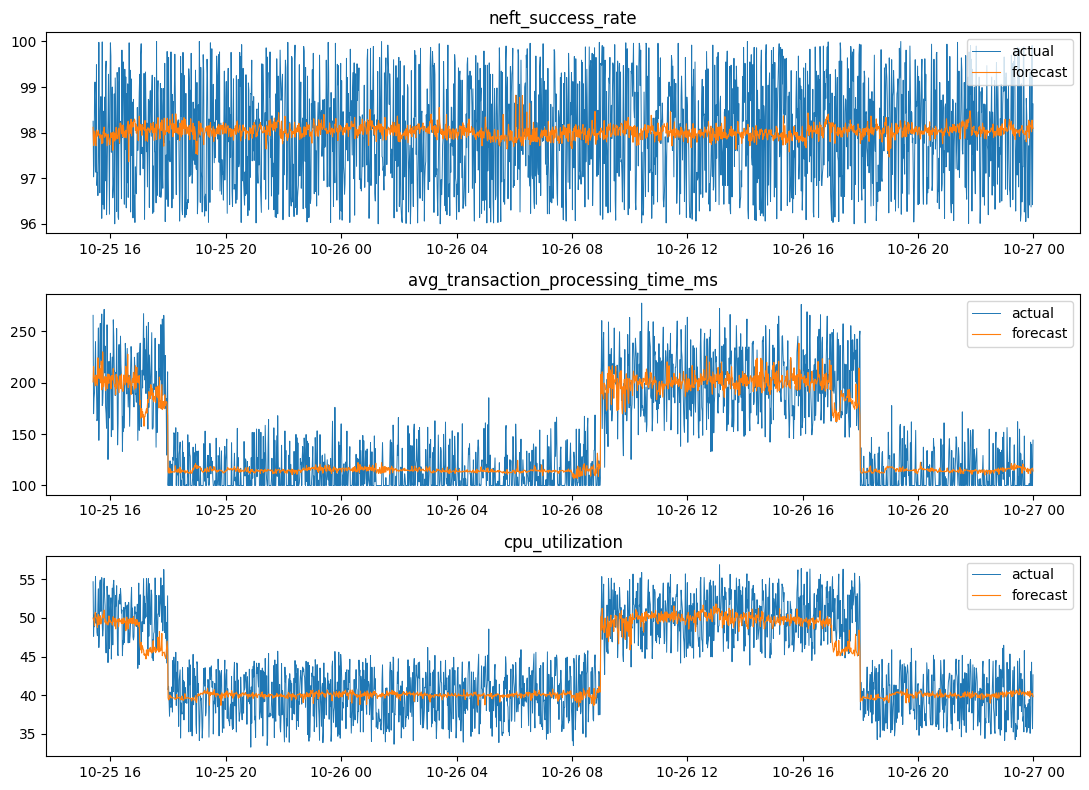

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8))

for ax, column in zip(axes, columns):
    test = forecast_tests[column]
    ax.plot(test.target_time, test.target, label='actual', linewidth=0.7)
    ax.plot(test.target_time, test.prediction, label='forecast', linewidth=0.8)
    ax.set_title(column)
    ax.legend()
plt.tight_layout()

The orange forecast line shows how the model is able to closely predict the values for each of these metrics. For the NEFT success rate, the actual values are mostly unpredictable noise around the same range, so the forecast is roughly around the average of those values.

### Build a classification model to predict incident criticality based on KPIs

Incident rows: 168
Critical incidents: 26

Classification report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       1.00      1.00      1.00         6

    accuracy                           1.00        42
   macro avg       1.00      1.00      1.00        42
weighted avg       1.00      1.00      1.00        42



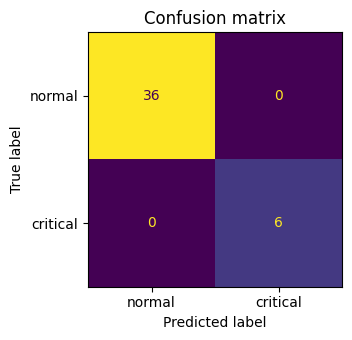

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

ir = pd.read_csv('../data/incident_reports.csv', parse_dates=['timestamp'])
print('Incident rows:', len(ir))
print('Critical incidents:', ir.is_critical.sum())
print()

kpis = ['cpu_utilization', 'memory_usage', 'db_connection_pool_usage',
        'network_throughput_mbps', 'application_error_rate', 'neft_success_rate',
        'imps_success_rate', 'rtgs_success_rate', 'avg_transaction_processing_time_ms']

X_train, X_test, y_train, y_test = train_test_split(ir[kpis], ir.is_critical, test_size=0.25, stratify=ir.is_critical, random_state=42)

classifier = RandomForestClassifier(
    n_estimators=100, 
    class_weight='balanced', 
    random_state=42
)

classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)

print('Classification report:\n', classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(4, 3.5))
ConfusionMatrixDisplay(cm, display_labels=['normal', 'critical']).plot(ax=ax, colorbar=False)
ax.set_title('Confusion matrix')
fig.tight_layout()

This model performed very well because the difference between critical and non-critical incidents is very clear. In task 1, it was shown that CPU utilization is 85.4% minimum for all critical incidents, and 76.4% maximum for non-critical incidents, so just filtering by CPU utilization can give 100% accuracy.

### Apply anomaly detection to identify unusual metric behavior

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, f1_score

scaler = StandardScaler()
X_anomaly_train = scaler.fit_transform(im_train[kpis])

anomaly_model = IsolationForest(contamination=0.01, random_state=42)
anomaly_model.fit(X_anomaly_train)

im_scaled = scaler.transform(im[kpis])
im_predictions = anomaly_model.predict(im_scaled) 
im_anomalies = im_predictions == -1

print(f'Anomalies in infrastructure_metrics:\n  {im_anomalies.sum()} of {len(im)} ({im_anomalies.mean():.1%})')

# Predict on incident_reports table and compare with is_critical status to check for overlap
ir_scaled = scaler.transform(ir[kpis])
ir_predictions = anomaly_model.predict(ir_scaled)
ir_anomalies = (ir_predictions == -1).astype(int)

print('\nEvaluation against critical incidents in incident_reports:')
print(f'precision: {precision_score(ir.is_critical, ir_anomalies):.3f}')
print(f'recall: {recall_score(ir.is_critical, ir_anomalies):.3f}')
print(f'F1: {f1_score(ir.is_critical, ir_anomalies):.3f}')

Anomalies in infrastructure_metrics:
  161 of 10080 (1.6%)

Evaluation against critical incidents in incident_reports:
precision: 0.897
recall: 1.000
F1: 0.945


An IsolationForest was used to identify anomalies. It was fit on the `infrastructure_metrics` training table, and then used to find anomalies on the entire table and on the `incident_reports` table. 

On the `infrastructure_metrics` table, it found 161 anomalies out of all 10,080 rows. 

On the `incident_reports` table, it was compared against the `is_critical` column. The precision, recall, and F1 metrics shown show that the anomalies it found mostly lined up with the critical rows. Therefore, this model can be used to spot critical server conditions.

### Evaluate model performance using metrics such as RMSE, MAE, Accuracy, and F1-score

Forecasting


,RMSE,Naive RMSE,MAE,Naive MAE
column,,,,
neft_success_rate,1.154,1.635,0.999,1.338
avg_transaction_processing_time_ms,25.470,43.732,20.219,31.210
cpu_utilization,3.270,5.288,2.723,4.141


Classification (RandomForestClassifier vs is_critical, hold-out set)


,score
accuracy,1.0
precision,1.0
recall,1.0
F1,1.0


Anomaly detection (IsolationForest vs is_critical, incident_reports)


,score
precision,0.897
recall,1.000
F1,0.945


Anomalies flagged: 161 of 10080 (1.6%)


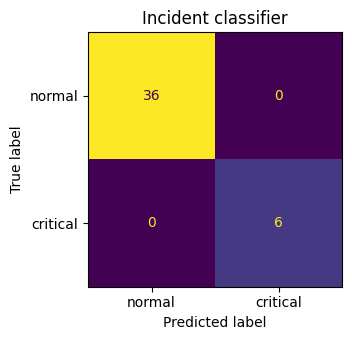

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

print('Forecasting')
display(forecast_results)

print('Classification (RandomForestClassifier vs is_critical, hold-out set)')
classifier_metrics = pd.Series({
    'accuracy': accuracy_score(y_test, y_pred),
    'precision': precision_score(y_test, y_pred),
    'recall': recall_score(y_test, y_pred),
    'F1': f1_score(y_test, y_pred),
}).round(3).to_frame('score')

display(classifier_metrics)

print('Anomaly detection (IsolationForest vs is_critical, incident_reports)')
anomaly_metrics = pd.Series({
    'precision': precision_score(ir.is_critical, ir_anomalies),
    'recall': recall_score(ir.is_critical, ir_anomalies),
    'F1': f1_score(ir.is_critical, ir_anomalies),
}).round(3).to_frame('score')

display(anomaly_metrics)

print(f'Anomalies flagged: {im_anomalies.sum()} of {len(im)} ({im_anomalies.mean():.1%})')

fig, ax = plt.subplots(figsize=(4, 3.5))
ConfusionMatrixDisplay(cm, display_labels=['normal', 'critical']).plot(ax=ax, colorbar=False)
ax.set_title('Incident classifier')
fig.tight_layout()

### Save trained models for deployment

In [8]:
import os
import joblib

os.makedirs('../models', exist_ok=True)

# Forecasting models
for column, model_info in forecast_models.items():
    joblib.dump(model_info, f'../models/forecast_{column}.joblib')

# Incident reports classifier
joblib.dump({'model': classifier, 'features': kpis}, '../models/incident_classifier.joblib')

# Anomaly detector
joblib.dump({'model': anomaly_model, 'scaler': scaler, 'features': kpis}, '../models/anomaly_detector.joblib')

saved_files = [f'forecast_{column}.joblib' for column in columns]
saved_files += ['incident_classifier.joblib', 'anomaly_detector.joblib']

print('Saved models:')
for file in saved_files:
    print(f'  models/{file}')

Saved models:
  models/forecast_neft_success_rate.joblib
  models/forecast_avg_transaction_processing_time_ms.joblib
  models/forecast_cpu_utilization.joblib
  models/incident_classifier.joblib
  models/anomaly_detector.joblib


All models were saved in the `models/` folder. Each file also stores the feature list that it expects so that they can be run without retraining later. The anomaly detector has its scaler saved because new rows have to be scaled before running predictions.